In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from pathlib import Path

PROJECT_DIR = Path.cwd().resolve()

if PROJECT_DIR.name == "02_Notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATASET_DIR = PROJECT_DIR / "03_Datasets"
RESULTS_DIR = PROJECT_DIR / "04_Results"
GRAPHS_DIR = PROJECT_DIR / "05_Graphs"

df = pd.read_csv(
    DATASET_DIR / "arbiter_puf_64bit_10000_crps.csv"
)

print("Dataset loaded successfully!")
print(df.head())
print("\nDataset shape:", df.shape)

Dataset loaded successfully!
                                           challenge  response
0  1100101001111111010100111011000011011010110010...         0
1  1000100010001110011100110110100110101011110101...         0
2  1111011010001000110010101001011111000100000011...         0
3  1010000101010011010110100001001010111001010110...         0
4  1001100111001100010001000010010110101011100001...         1

Dataset shape: (10000, 2)


In [2]:
from sklearn.model_selection import train_test_split

X_raw = np.array([
    [int(bit) for bit in str(challenge).zfill(64)]
    for challenge in df["challenge"]
])

X_bipolar = np.where(X_raw == 1, 1, -1)

X_transformed = np.flip(
    np.cumprod(
        np.flip(X_bipolar, axis=1),
        axis=1
    ),
    axis=1
)

y = df["response"].to_numpy()

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train_phi, X_test_phi, _, _ = train_test_split(
    X_transformed,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train_raw))
print("Testing samples:", len(X_test_raw))
print("Raw feature shape:", X_train_raw.shape)
print("Transformed feature shape:", X_train_phi.shape)
print("All challenges have 64 bits:", X_raw.shape[1] == 64)

Training samples: 8000
Testing samples: 2000
Raw feature shape: (8000, 64)
Transformed feature shape: (8000, 64)
All challenges have 64 bits: True


In [3]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

mlp_raw = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        max_iter=300,
        early_stopping=True,
        n_iter_no_change=15,
        random_state=42
    )
)

start = time.perf_counter()

mlp_raw.fit(X_train_raw, y_train)

mlp_raw_time = time.perf_counter() - start

mlp_raw_predictions = mlp_raw.predict(X_test_raw)

mlp_raw_accuracy = accuracy_score(
    y_test,
    mlp_raw_predictions
)

print("MLP - Raw Challenges")
print("--------------------")
print("Accuracy:",
      round(mlp_raw_accuracy * 100, 2), "%")
print("Training time:",
      round(mlp_raw_time, 4), "seconds")

print("Training iterations:",
      mlp_raw[-1].n_iter_)

MLP - Raw Challenges
--------------------
Accuracy: 53.6 %
Training time: 2.1651 seconds
Training iterations: 24


In [4]:
mlp_transformed = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        max_iter=300,
        early_stopping=True,
        n_iter_no_change=15,
        random_state=42
    )
)

start = time.perf_counter()

mlp_transformed.fit(X_train_phi, y_train)

mlp_transformed_time = time.perf_counter() - start

mlp_transformed_predictions = mlp_transformed.predict(X_test_phi)

mlp_transformed_accuracy = accuracy_score(
    y_test,
    mlp_transformed_predictions
)

print("MLP - Transformed Challenges")
print("----------------------------")
print("Accuracy:",
      round(mlp_transformed_accuracy * 100, 2), "%")
print("Training time:",
      round(mlp_transformed_time, 4), "seconds")

print("Training iterations:",
      mlp_transformed[-1].n_iter_)

MLP - Transformed Challenges
----------------------------
Accuracy: 96.4 %
Training time: 2.096 seconds
Training iterations: 23


In [5]:
lr_results = pd.read_csv(
    RESULTS_DIR / "lr_feature_comparison.csv"
)

lr_results["Model"] = [
    "Logistic Regression - Raw",
    "Logistic Regression - Transformed"
]

mlp_results = pd.DataFrame([
    {
        "Model": "MLP - Raw",
        "Accuracy (%)": mlp_raw_accuracy * 100,
        "Training Time (s)": mlp_raw_time
    },
    {
        "Model": "MLP - Transformed",
        "Accuracy (%)": mlp_transformed_accuracy * 100,
        "Training Time (s)": mlp_transformed_time
    }
])

comparison_results = pd.concat(
    [lr_results, mlp_results],
    ignore_index=True
)

display(comparison_results)

,Model,Accuracy (%),Training Time (s)
0,Logistic Regression - Raw,54.90,0.029158
1,Logistic Regression - Transformed,98.95,0.037014
2,MLP - Raw,53.60,2.165143
3,MLP - Transformed,96.40,2.095972


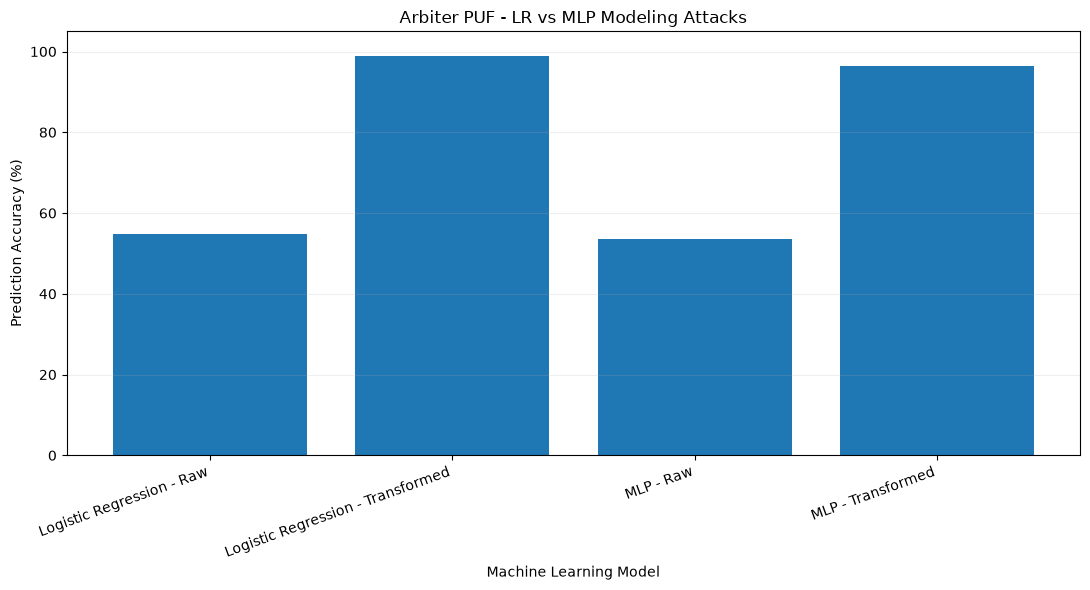

In [6]:
plt.figure(figsize=(11, 6))

plt.bar(
    comparison_results["Model"],
    comparison_results["Accuracy (%)"]
)

plt.ylabel("Prediction Accuracy (%)")
plt.xlabel("Machine Learning Model")

plt.title("Arbiter PUF - LR vs MLP Modeling Attacks")

plt.ylim(0, 105)
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()

plt.savefig(
    GRAPHS_DIR / "lr_vs_mlp_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
comparison_results.to_csv(
    RESULTS_DIR / "lr_vs_mlp_comparison.csv",
    index=False
)

print("MLP experiment results saved successfully!")

MLP experiment results saved successfully!
